## Tujuan Pembelajaran:

* Memperoleh pengantar tentang struktur data **DataFrame** dan **Series** dari *library* pandas
* Mengakses dan memanipulasi data di dalam **DataFrame** dan **Series**
* Mengimpor data CSV ke dalam pandas **DataFrame**
* Melakukan *reindex* pada **DataFrame** untuk mengacak data

pandas adalah API analisis data berorientasi kolom. Ini adalah alat yang hebat untuk menangani dan menganalisis data masukan, dan banyak *framework* ML mendukung struktur data pandas sebagai masukan. Meskipun pengenalan komprehensif terhadap API pandas akan memakan banyak halaman, konsep-konsep intinya cukup mudah, dan akan kami sajikan di bawah. Untuk referensi yang lebih lengkap, situs [dokumen pandas](https://pandas.pydata.org/pandas-docs/stable/index.html) berisi dokumentasi ekstensif dan banyak tutorial.

# Konsep Dasar

Baris berikut mengimpor API pandas dan mencetak versi API:

In [1]:
from __future__ import print_function

import pandas as pd
pd.__version__

'2.2.3'

Struktur data utama dalam pandas diimplementasikan sebagai dua kelas:

* **DataFrame**, yang dapat Anda bayangkan sebagai tabel data relasional, dengan baris dan kolom bernama.
* **Series**, yang merupakan kolom tunggal. Sebuah **DataFrame** berisi satu atau lebih **Series** dan nama untuk setiap **Series**.

DataFrame adalah abstraksi yang umum digunakan untuk manipulasi data. Implementasi serupa ada di Spark dan R.

Salah satu cara untuk membuat **Series** adalah dengan membuat objek **Series**. Contohnya:

In [2]:
pd.Series(['San Francisco', 'San Jose', 'Sacramento'])

0    San Francisco
1         San Jose
2       Sacramento
dtype: object

Objek **DataFrame** dapat dibuat dengan meneruskan *dict* yang memetakan nama kolom *string* ke **Series** masing-masing. Jika panjang **Series** tidak cocok, nilai yang hilang diisi dengan nilai khusus NA/NaN. Contoh:

In [3]:
city_names = pd.Series(['San Francisco', 'San Jose', 'Sacramento'])
population = pd.Series([852469, 1015785, 485199])

pd.DataFrame({ 'City name': city_names, 'Population': population })

,City name,Population
0,San Francisco,852469
1,San Jose,1015785
2,Sacramento,485199


Namun sebagian besar waktu, Anda memuat seluruh *file* ke dalam **DataFrame**. Contoh berikut memuat *file* dengan data perumahan California. Jalankan sel berikut untuk memuat data dan membuat definisi *fitur*:

In [4]:
california_housing_dataframe = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/california_housing_train.csv", sep=",")
california_housing_dataframe.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Contoh di atas menggunakan `DataFrame.describe` untuk menunjukkan statistik menarik tentang **DataFrame**. Fungsi lainnya adalah `DataFrame.head`, yang menampilkan beberapa catatan pertama dari **DataFrame**:

In [5]:
california_housing_dataframe.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


Fitur kuat lain dari pandas adalah pembuatan grafik. Misalnya, `DataFrame.hist` memungkinkan Anda mempelajari distribusi nilai dalam kolom dengan cepat:

array([[<Axes: title={'center': 'housing_median_age'}>]], dtype=object)

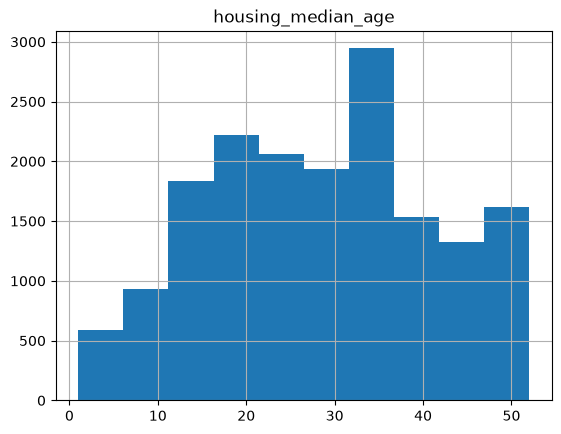

In [6]:
california_housing_dataframe.hist('housing_median_age')

# Mengakses Data

Anda dapat mengakses data **DataFrame** menggunakan operasi *dict/list* Python yang sudah dikenal:

In [7]:
cities = pd.DataFrame({ 'City name': city_names, 'Population': population })

print(type(cities['City name']))
cities['City name']

<class 'pandas.core.series.Series'>


0    San Francisco
1         San Jose
2       Sacramento
Name: City name, dtype: object

In [8]:
print(type(cities['City name'][1]))
cities['City name'][1]

<class 'str'>


'San Jose'

In [9]:
print(type(cities[0:2]))
cities[0:2]

<class 'pandas.core.frame.DataFrame'>


,City name,Population
0,San Francisco,852469
1,San Jose,1015785


Selain itu, pandas menyediakan API yang sangat kaya untuk pengindeksan dan pemilihan lanjutan yang terlalu luas untuk dibahas di sini.

# Memanipulasi Data

Anda dapat menerapkan operasi aritmatika dasar Python ke **Series**. Contohnya:

In [10]:
population / 1000.

0     852.469
1    1015.785
2     485.199
dtype: float64

NumPy adalah *toolkit* populer untuk komputasi ilmiah. pandas **Series** dapat digunakan sebagai argumen untuk sebagian besar fungsi NumPy:

In [11]:
import numpy as np
np.log(population)

0    13.655892
1    13.831172
2    13.092314
dtype: float64

Untuk transformasi kolom tunggal yang lebih kompleks, Anda dapat menggunakan `Series.apply`. Seperti fungsi *map* Python, `Series.apply` menerima fungsi *lambda* sebagai argumen, yang diterapkan pada setiap nilai.

Contoh di bawah ini membuat **Series** baru yang menunjukkan apakah populasi di atas satu juta:

In [12]:
population.apply(lambda val: val > 1000000)

0    False
1     True
2    False
dtype: bool

Memodifikasi **DataFrame** juga mudah. Misalnya, kode berikut menambahkan dua **Series** ke **DataFrame** yang sudah ada:

In [13]:
cities['Area square miles'] = pd.Series([46.87, 176.53, 97.92])
cities['Population density'] = cities['Population'] / cities['Area square miles']
cities

,City name,Population,Area square miles,Population density
0,San Francisco,852469,46.87,18187.945381
1,San Jose,1015785,176.53,5754.177760
2,Sacramento,485199,97.92,4955.055147


# Mari kita mulai

In [2]:
# NIM Anda di sini
nim = '202310370311317'
print(f'NIM: {nim}')

NIM: 202310370311317


In [4]:
# Nama Anda di sini
nama = 'Muhammad Fajar Nurilham Jaya'
print(f'Nama: {nama}')

Nama: Muhammad Fajar Nurilham Jaya


# Latihan #1

Modifikasi tabel kota dengan menambahkan kolom boolean baru, yang bernilai **True** jika dan hanya jika kedua hal berikut ini Benar:

1. Nama kota diawali oleh suku kata `San` (*saint*).
2. Kota tersebut memiliki luas lebih dari 50 mil persegi.

**Catatan**: Boolean **Series** digabungkan menggunakan operator ***bitwise***, bukan operator boolean tradisional. Misalnya, saat melakukan *logical and*, gunakan `&` alih-alih `and`.

In [14]:
cities['Area square miles'] > 50

0    False
1     True
2     True
Name: Area square miles, dtype: bool

In [15]:
cities['City name'].apply(lambda nama: nama.startswith('San'))

0     True
1     True
2    False
Name: City name, dtype: bool

In [19]:
# Kode Anda di sini

cities['Is wide and has saint name'] = (
    (cities['Area square miles'] > 50) &
    (cities['City name'].apply(lambda nama: nama.startswith('San'))) 
)

cities

,City name,Population,Area square miles,Population density,Is wide and has saint name
0,San Francisco,852469,46.87,18187.945381,False
1,San Jose,1015785,176.53,5754.177760,True
2,Sacramento,485199,97.92,4955.055147,False


# Indeks

Baik objek **Series** maupun **DataFrame** juga mendefinisikan properti *index* yang menetapkan nilai pengenal untuk setiap item **Series** atau baris **DataFrame**.

Secara *default*, saat konstruksi, pandas menetapkan nilai indeks yang mencerminkan urutan data sumber. Setelah dibuat, nilai indeks bersifat stabil; artinya, nilai tersebut tidak berubah ketika data diurutkan ulang.

In [20]:
city_names.index

RangeIndex(start=0, stop=3, step=1)

In [21]:
cities.index

RangeIndex(start=0, stop=3, step=1)

Panggil `DataFrame.reindex` untuk mengurutkan ulang baris secara manual. Misalnya, baris berikut memiliki efek yang sama dengan mengurutkan berdasarkan nama kota:

In [22]:
cities.reindex([2, 0, 1])

,City name,Population,Area square miles,Population density,Is wide and has saint name
2,Sacramento,485199,97.92,4955.055147,False
0,San Francisco,852469,46.87,18187.945381,False
1,San Jose,1015785,176.53,5754.177760,True


*Reindexing* adalah cara yang bagus untuk mengacak (*shuffle*/me-randomisasi) **DataFrame**. Dalam contoh di bawah, kita mengambil indeks, yang menyerupai *array*, dan meneruskannya ke fungsi NumPy `random.permutation`, yang mengacak nilainya di tempat. Memanggil *reindex* dengan *array* yang diacak ini menyebabkan baris **DataFrame** diacak dengan cara yang sama. Coba jalankan sel berikut beberapa kali!

In [23]:
cities.reindex(np.random.permutation(cities.index))

,City name,Population,Area square miles,Population density,Is wide and has saint name
0,San Francisco,852469,46.87,18187.945381,False
1,San Jose,1015785,176.53,5754.177760,True
2,Sacramento,485199,97.92,4955.055147,False


Untuk informasi lebih lanjut, lihat [dokumentasi Index](https://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing).

# Latihan #2

Metode `reindex` memungkinkan untuk menambahkan indeks baru ke **DataFrame** asli. Coba dan lihat apa yang terjadi jika Anda menggunakan nilai tersebut! Menurut Anda mengapa ini diizinkan?

In [24]:
# Kode Anda di sini
indeks_baru = [0, 4, 5, 2]

# panggil fungsi reindex dengan argumen index_baru
cities = cities.reindex([0, 4, 5, 2])

# print baris data dengan nilai kolom yang semuanya NaN
print(cities[cities.isna().all(axis=1)])

# print jumlah baris kolom yang semuanya NaN
print(cities.isna().all(axis=1).sum())

# TIPS: gunakan fungsi isna()

  City name  Population  Area square miles  Population density  \
4       NaN         NaN                NaN                 NaN   
5       NaN         NaN                NaN                 NaN   

  Is wide and has saint name  
4                        NaN  
5                        NaN  
2


Menurut saya, ini diizinkan karena reindex berjalan berdasarkan label indeks, jadi saat reindex diberi label yang tidak ada maka nanti pandas tidak akan menghasilkan eror tetapi membuat baris baru yang seluruh kolomnya bernilai NaN.